In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import scripts.common as cmn
import scripts.weight as wght

## RF-DETR: необязательный выбор

Установите `rfdetr[train]==1.12.1` в окружении ноутбука. Доступны варианты
`rf-detr-n/s/m/l` и `rf-detr-seg-n/s/m/l` (каждый суффикс — отдельный ключ).
Измените флаги ниже до скачивания; остальные выбранные модели сохраняются.
Для сегментации нужен отдельный YAML с полигонами и `task="segment"`;
размер 640 подходит детекторам, для сегментации используйте, например, 384.
При предсказании `imgsz` должен совпадать с разрешением загруженной модели.


In [3]:
# Раскомментируйте нужные модели перед скачиванием.
# cmn.MODELS["rf-detr-m"] = True
# cmn.MODELS["rf-detr-seg-s"] = True


In [4]:
wght.inspect_weights()

,model,backend,task,status,original,trained,checkpoint
0,yolov8n,ultralytics,detect,Ready,True,True,yolov8n.pt
1,yolo26n,ultralytics,detect,Ready,True,True,yolo26n.pt
2,rf-detr-m,rfdetr,detect,Ready,False,False,rf-detr-medium.pth


In [5]:
wght.download_weights()

,status,size (MiB),file
model,,,
yolov8n,Already exists,,yolov8n.pt
yolo26n,Pending,,yolo26n.pt
rf-detr-m,Pending,,rf-detr-medium.pth


/home/natsusa/academic/tobacco-article/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-11-14 16:53:05] [INFO] rf-detr - Downloading pretrained weights for /home/natsusa/academic/tobacco-article/weights/original/download-v_14etut/rf-detr-medium.pth


/home/natsusa/academic/tobacco-article/weights/original/download-v_14etut/rf-detr-medium.pth: 100%|██████████| 386M/386M [22:06<00:00, 305kiB/s]    


[2026-11-14 17:15:12] [INFO] rf-detr - MD5 validation successful for /home/natsusa/academic/tobacco-article/weights/original/download-v_14etut/rf-detr-medium.pth


## Реестр и выбор моделей

`cmn.MODELS` остаётся единственным словарём включения и отключения моделей.
`cmn.MODELS_REGESTRY` содержит метаданные реализаций с теми же ключами.
Для семейства необходимо явно указать файл весов: размер модели автоматически
не выбирается. При скачивании используется имя файла из реестра, которое может
отличаться от локального идентификатора модели.

Реализованы бэкенды Ultralytics и RF-DETR. MMDetection зарезервирован
для будущего адаптера. Остальные реализации отключены и снабжены комментариями.
При обучении неподдерживаемые записи пропускаются с указанием причины;
некорректный датасет или ошибка обучения останавливают выполнение.
Существующие файлы `weights/trained/<model-id>.pt` пропускаются: повторный
запуск обучает только модели, для которых обученные веса ещё не сохранены.


In [6]:
from scripts.contracts import DatasetSpec, TrainConfig, ModelArtifacts
from scripts.workflows import train_models, load_model

# Текущий датасет содержит разметку для детекции. Для сегментации экземпляров
# укажите YAML датасета YOLO с полигональной разметкой и task="segment".
dataset = DatasetSpec(cmn.DATA_YAML, task="detect")
training_config = TrainConfig(
    epochs=1,
    image_size=640,
    batch=1,
    device="cpu",  # При необходимости замените на "cuda:0" или "mps".
    seed=0,
    backend_options={
        "ultralytics": {"workers": 0, "plots": True},
        "rfdetr": {"num_workers": 0},
    },
)


In [7]:
# Обучаются только включённые модели без файла weights/trained/<model-id>.pt.
RUN_TRAINING = True
training_batch = None
if RUN_TRAINING:
    training_batch = train_models(dataset, training_config)
    print("Completed:", list(training_batch.runs))
    print("Skipped:", training_batch.skipped)
else:
    print("Training disabled. Set RUN_TRAINING=True to execute the configured training run.")


Val (ema) (Epoch 1/1) — Overall Metrics             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.0171 │ 0.0236 │ 0.0187 │ 0.0153 │ 0.0382 │ 0.2831 │ 0.0205 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

[2026-11-14 17:17:16] [INFO] rf-detr - Best EMA metric improved to 0.0171 (epoch 0)


`Trainer.fit` stopped: `max_epochs=1` reached.


[2026-11-14 17:17:19] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.0171)
Completed rf-detr-m: /home/natsusa/academic/tobacco-article/experiments/reproductions/rf-detr-m-20261114T141512Z-332dd893
Completed: ['rf-detr-m']
Skipped: {'yolov8n': 'Trained weights already exist: /home/natsusa/academic/tobacco-article/weights/trained/yolov8n.pt', 'yolo26n': 'Trained weights already exist: /home/natsusa/academic/tobacco-article/weights/trained/yolo26n.pt'}


## Загрузка результата конкретного запуска и предсказание

Каждый запуск сохраняет лучшие и последние веса, а также `manifest.json`
с описанием модели, версией пакета, фактическими настройками обучения,
хешами датасета и выборок и метриками. Копия в `weights/trained/<model-id>.pt`
содержит веса последнего успешного запуска; для воспроизводимости используйте
артефакт конкретного эксперимента.

Общий интерфейс предсказания принимает путь к локальному изображению, изображение
PIL или массив NumPy формы H×W×3 с типом `uint8` и порядком каналов **BGR**.
Рамки и маски используют координаты исходного изображения. Исходные результаты
провайдера доступны для визуализации.


[2026-11-14 17:17:19] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


Boxes: []
Classes: []


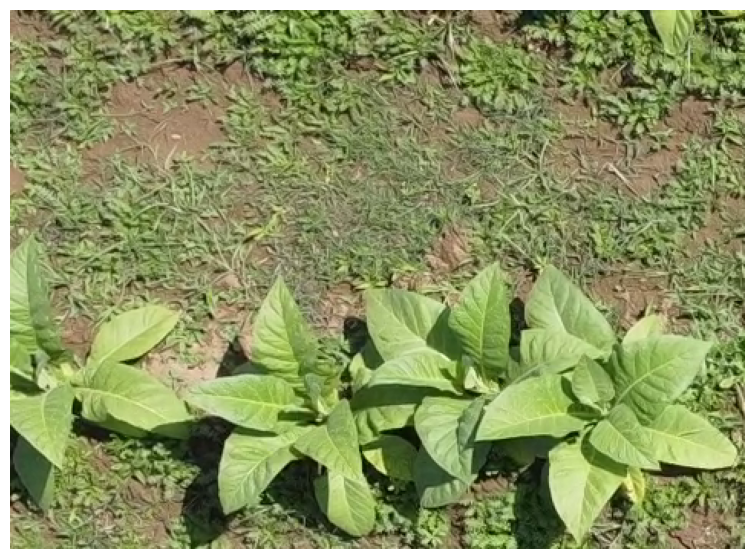

In [8]:
MODEL_TO_INSPECT = "rf-detr-m"
IMAGE_PATH = cmn.DATASET_PATH / "images" / "image_000001.png"

if training_batch is not None and MODEL_TO_INSPECT in training_batch.runs:
    run = training_batch.runs[MODEL_TO_INSPECT]
    predictor = load_model(MODEL_TO_INSPECT, run.best_artifacts, device=training_config.device)
    predictions = predictor.predict(IMAGE_PATH, imgsz=640, conf=0.25)
    for prediction in predictions:
        print("Boxes:", prediction.boxes_xyxy)
        print("Classes:", prediction.class_ids)
        import matplotlib.pyplot as plt
        from scripts.visualization import plot_prediction
        plot_prediction(IMAGE_PATH, prediction)
        plt.show()
else:
    print("Train the chosen model first, or explicitly load an existing run checkpoint.")

# Для загрузки предыдущего запуска укажите точный путь к его весам:
# artifacts = ModelArtifacts(cmn.RUNS_DIR / "<run-name>" / "weights" / "best.pt")
# predictor = load_model(MODEL_TO_INSPECT, artifacts, device=training_config.device)


## Необязательный пример предсказания по подсказкам

Предсказание по подсказкам не зависит от обучения. Адаптер предоставляет
предсказание для SAM, MobileSAM, SAM 2, SAM 3 и FastSAM, но не заявляет
поддержку их обучения через Ultralytics. В нормализованном результате маскам
без семантических классов не назначаются вымышленные идентификаторы классов.

Примеры ниже используют явные спецификации и не изменяют `MODELS`.
По умолчанию выполнение отключено, поскольку файлы весов могут быть большими.
Для SAM 3 может потребоваться ручное получение весов с разрешением доступа:
перед использованием поместите `sam3.pt` в `cmn.ORIGINAL_WEIGHTS_DIR`.


In [9]:
from dataclasses import replace
from scripts.backends import get_backend

RUN_PROMPT_EXAMPLE = False
# Явно задаём вариант семейства SAM; для других семейств используется тот же подход.
prompt_spec = replace(cmn.MODELS_REGESTRY["sam"], checkpoint="sam_b.pt")
if RUN_PROMPT_EXAMPLE:
    backend = get_backend(prompt_spec)
    artifacts = backend.download(prompt_spec)
    prompted = backend.load(prompt_spec, artifacts, device=training_config.device)
    masks = prompted.predict(IMAGE_PATH, prompts={"points": [[100, 100]], "labels": [1]})
    masks[0].native.show()

# Другие виды подсказок (координаты должны соответствовать выбранному изображению):
# YOLOWorld: prompts={"text": ["tobacco", "weed"]}
# YOLOE: prompts={"text": ["tobacco"]}
# YOLOE: prompts={"visual_prompts": {"bboxes": [[10, 10, 100, 100]], "cls": [0]}}
# FastSAM: prompts={"text": ["leaf"]} или {"bboxes": [[10, 10, 100, 100]]}
# SAM/MobileSAM/SAM2/SAM3, интерактивный режим: prompts={"points": [[100, 100]], "labels": [1]}
# SAM3, поиск по понятиям: prompts={"text": ["tobacco"]} или {"exemplars": [[10, 10, 100, 100]]}
# Сопровождение объектов на видео с сохранением состояния не входит в этот API.
